In [3]:
%matplotlib inline
import math
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

Based on the provided pages from *Dive into Deep Learning* (Section 9.4: **Recurrent Neural Networks**), here is a detailed, step-by-step breakdown of how Recurrent Neural Networks (RNNs) solve the parameter explosion of $n$-grams by introducing **hidden states** and **recurrent computation**.

---

## 1. The Limitation of $n$-grams & The Need for Latent Variables

As discussed in earlier sections, $n$-gram language models approximate conditional probabilities using a fixed window of size $n$:


$$P(x_t \mid x_{t-1}, \dots, x_1) \approx P(x_t \mid x_{t-1}, \dots, x_{t-n+1})$$

* **The Problem:** To capture longer dependencies, we must increase $n$. However, this causes the number of model parameters to **grow exponentially** ($\mathcal{V}^n$, where $\mathcal{V}$ is the vocabulary size).


* **The Latent Variable Solution:** Instead of conditioning on an expanding window of raw history, we introduce a **hidden state** $h_{t-1}$ that summarizes all sequence information up to time step $t-1$:



$$P(x_t \mid x_{t-1}, \dots, x_1) \approx P(x_t \mid h_{t-1})$$



The hidden state is updated recursively via a function of the current input and previous hidden state:



$$h_t = f(x_t, h_{t-1})$$






---

## 2. From Standard MLPs to Recurrent Neural Networks

### Feedforward Neural Networks (Without Hidden States)

In a standard Multilayer Perceptron (MLP) with a single hidden layer, given a minibatch of inputs $\mathbf{X} \in \mathbb{R}^{n \times d}$ (batch size $n$, input dimension $d$), the hidden layer output $\mathbf{H}$ is:


$$\mathbf{H} = \phi(\mathbf{X}\mathbf{W}_{xh} + \mathbf{b}_h)$$


where $\mathbf{W}_{xh}$ are input-to-hidden weights, $\mathbf{b}_h$ is the bias, and $\phi$ is an activation function. The final output is:


$$\mathbf{O} = \mathbf{H}\mathbf{W}_{hq} + \mathbf{b}_q$$



### Recurrent Neural Networks (With Hidden States)

In an RNN, matters change because the hidden state at time step $t$ ($\mathbf{H}_t$) depends on **both** the current input matrix $\mathbf{X}_t$ *and* the hidden state from the previous time step ($\mathbf{H}_{t-1}$):

$$\mathbf{H}_t = \phi(\mathbf{X}_t \mathbf{W}_{xh} + \mathbf{H}_{t-1} \mathbf{W}_{hh} + \mathbf{b}_h)$$



* **$\mathbf{W}_{xh} \in \mathbb{R}^{d \times h}$:** Weights mapping the current input to the hidden state.


* **$\mathbf{W}_{hh} \in \mathbb{R}^{h \times h}$:** Weights mapping the *previous* hidden state to the *current* hidden state (this is what makes the network **recurrent**).


* **$\mathbf{O}_t = \mathbf{H}_t \mathbf{W}_{hq} + \mathbf{b}_q$:** The output at time step $t$.

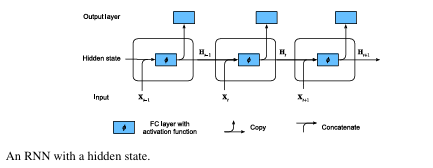



### Why RNN Parameters Do Not Grow with Time

Even as a sequence grows arbitrarily long ($T \rightarrow \infty$), **the parameter matrices ($\mathbf{W}_{xh}, \mathbf{W}_{hh}, \mathbf{W}_{hq}$) are shared across all time steps**. The same weights are reused recursively at every step, meaning the model's memory footprint remains constant regardless of sequence length.

---

## 3. Computational Equivalence: Concatenation vs. Separate Summation

Mathematically, the hidden state update:


$$\mathbf{X}_t \mathbf{W}_{xh} + \mathbf{H}_{t-1} \mathbf{W}_{hh}$$


is completely equivalent to **concatenating** the input matrix $\mathbf{X}_t$ and previous hidden state $\mathbf{H}_{t-1}$ along columns, and concatenating the weight matrices $\mathbf{W}_{xh}$ and $\mathbf{W}_{hh}$ along rows, then performing a single matrix multiplication:


$$\text{concat}(\mathbf{X}_t, \mathbf{H}_{t-1}, \text{axis}=1) \times \text{concat}(\mathbf{W}_{xh}, \mathbf{W}_{hh}, \text{axis}=0)$$



---

## 4. Concrete Example: RNN-Based Character-Level Language Model

To see how this works in practice, let's look at the character-level language model illustrated in Figure 9.4.2:

* **Input Sequence:** `"m a c h i n"`


* **Target Sequence (shifted by 1):** `"a c h i n e"`



### Step-by-Step Execution:

1. **Time Step $t=1$:**
* Input character $x_1 =$ `"m"` is fed into the network along with an initial hidden state $\mathbf{H}_0$ (usually initialized to zeros).
* The hidden state updates to $\mathbf{H}_1 = \phi(\mathbf{X}_1 \mathbf{W}_{xh} + \mathbf{H}_{0} \mathbf{W}_{hh} + \mathbf{b}_h)$.


* The output layer computes $\mathbf{O}_1$, and a softmax layer produces a probability distribution over the vocabulary to predict the next character.


* The target label is $y_1 =$ `"a"`. Cross-entropy loss measures the error between prediction $\mathbf{O}_1$ and target `"a"`.




2. **Time Step $t=2$:**
* Input character $x_2 =$ `"a"` is fed in, but crucially, the network *also* receives the hidden state $\mathbf{H}_1$ carrying memory from `"m"`.


* $\mathbf{H}_2$ is computed, incorporating context from both `"m"` and `"a"`.
* The model predicts the next character, with the target label $y_2 =$ `"c"`.




3. This process repeats sequentially up to $T$, allowing the hidden state chain ($\mathbf{H}_1 \rightarrow \mathbf{H}_2 \rightarrow \mathbf{H}_3 \dots$) to accumulate historical context across the entire string.

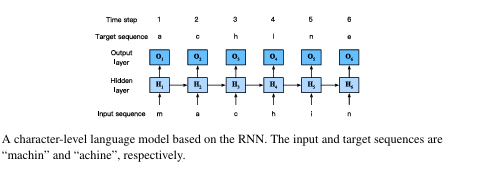

### 1. If we use an RNN to predict the next character in a text sequence, what is the required dimension for any output?

* For a minibatch of size $n$, the output matrix $\mathbf{O}_t$ at any given time step $t$ must have the dimension **$n \times \vert{}\mathcal{V}\vert{}$** (where $\vert{}\mathcal{V}\vert{}$ is the size of the vocabulary).


* This is because the model acts as a probabilistic classifier that outputs a score/probability distribution over every possible token in the vocabulary for each sequence in the minibatch.



---

### 2. Why can RNNs express the conditional probability of a token at some time step based on all the previous tokens in the text sequence?

* RNNs achieve this through **recurrent computation**, where the hidden state $\mathbf{H}_{t-1}$ acts as a memory vector that recursively accumulates and carries forward historical information from all preceding inputs $\mathbf{X}_1, \dots, \mathbf{X}_{t-1}$.


* Because the update rule $\mathbf{H}_t = \phi(\mathbf{X}_t\mathbf{W}_{xh} + \mathbf{H}_{t-1}\mathbf{W}_{hh} + \mathbf{b}_h)$ depends on the previous hidden state, the context of the entire past sequence is compressed into and represented by the current hidden state.



---

### 3. What happens to the gradient if you backpropagate through a long sequence?

* When performing Backpropagation Through Time (BPTT) over a very long sequence, gradients are prone to **vanishing or exploding**.


* This occurs because the chain rule requires repeatedly multiplying the recurrent weight matrix $\mathbf{W}_{hh}$ across many time steps. If the eigenvalues of $\mathbf{W}_{hh}$ are small, gradients decay exponentially to zero (vanishing); if they are large, gradients grow exponentially toward infinity (exploding).



---

### 4. What are some of the problems associated with the language model described in this section?

* **Lack of Parallelization:** Because the hidden state at step $t$ strictly depends on the hidden state from step $t-1$, computations cannot be parallelized across time steps during training, making training slow for long sequences.


* **Gradient Instability:** Standard RNNs struggle to capture very long-range dependencies due to the vanishing and exploding gradient problem over extended time horizons.


* **Information Bottleneck:** A fixed-size hidden state vector has limited capacity, making it difficult to perfectly retain and compress all intricate details from extremely long historical contexts.

In [5]:
class RNNScratch(d2l.Module):
    """RNN implementation from scratch"""
    def __init__(self, num_inputs, num_hiddens, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W_xh = nn.Parameter(torch.randn(num_inputs, num_hiddens) * sigma)
        self.W_hh = nn.Parameter(torch.rand(num_hiddens, num_hiddens) * sigma)
        self.b_h = nn.Parameter(torch.zeros(num_hiddens))

    def forward(self, inputs, state=None):
        if state is None:
            state = torch.zeros((inputs.shape[1], self.num_hiddens))
        else:
            state, = state

        outputs = []    
        # iterate over time steps
        for X in inputs:
            state = torch.tanh(
                torch.matmul(X, self.W_xh) + torch.matmul(state, self.W_hh) + self.b_h
            )
            outputs.append(state)

        return outputs, state
    

In [6]:
batch_size, num_inputs, num_hiddens, num_steps = 2, 16, 32, 100

In [7]:
rnn = RNNScratch(num_inputs, num_hiddens)
X = torch.ones((num_steps, batch_size, num_inputs))
outputs, state = rnn(X)

def check_len(a, n): #@save
    """Check the length of a list."""
    assert len(a) == n, f'list\'s length {len(a)} != expected length {n}'

def check_shape(a, shape): #@save
    """Check the shape of a tensor."""
    assert a.shape == shape, \
    f'tensor\'s shape {a.shape} != expected shape {shape}'

In [8]:
check_len(outputs, num_steps)
check_shape(outputs[0], (batch_size, num_hiddens))
check_shape(state, (batch_size, num_hiddens))

In [19]:
class RNNLMScratch(d2l.Module):
    """RNN-based language model implementation from scratch."""
    def __init__(self, rnn, vocab_size, lr=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.init_params()
    
    def init_params(self):
        self.W_hq = torch.randn(self.rnn.num_hiddens, self.vocab_size) * self.rnn.sigma
        self.b_q = torch.zeros(self.vocab_size)

    def training_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1]) 
        self.plot('ppl', torch.exp(l), train=True)
        return l
    
    def validation_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1]) 
        self.plot('ppl', torch.exp(l), train=True)

    def one_hot(self, X):
        # Output shape = (num_steps, batch_size, vocab_size)
        return F.one_hot(X.T, self.vocab_size).type(torch.float32)
    
    """The language model uses a fully connected output layer to transform RNN outputs into token predictions at each time step."""
    def output_layer(self, rnn_outputs):
        outputs = [torch.matmul(H, self.W_hq) + self.b_q for H in rnn_outputs]
        return torch.stack(outputs, 1)
    
    def forward(self, X, state=None):
        embs = self.one_hot(X)
        rnn_outputs = self.rnn(embs, state)
        return self.output_layer(rnn_outputs)


In [20]:
model = RNNLMScratch(rnn, num_inputs)
outputs = model(torch.ones((batch_size, num_steps), dtype=torch.int64))
check_shape(outputs, (batch_size, num_steps, num_inputs))

TypeError: matmul(): argument 'input' (position 1) must be Tensor, not list